## Workshop : 01
## Sturdy Octo Disco Adding Sunglasses for a Cool New Look
**Name :** MONISHA S **Reg. No :** 212225040258

In [29]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

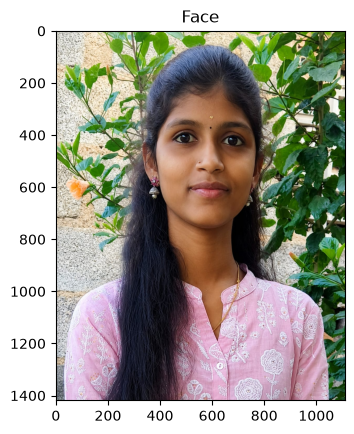

In [30]:
# Load the Face Image
faceImage = cv2.imread("PHOTO.jpeg")
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")




In [31]:
faceImage.shape

(1419, 1109, 3)

In [32]:
#resized_faceImage.shape
faceImage.shape

(1419, 1109, 3)

Text(0.5, 1.0, 'glassPNG')

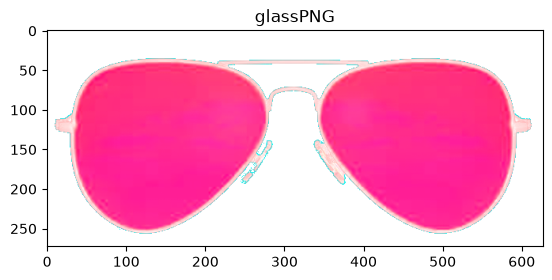

In [33]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('Image-Source-PlusPNG.com.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [34]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [35]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

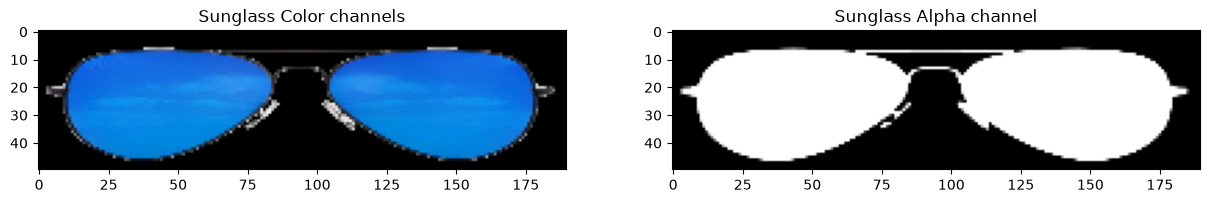

In [36]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

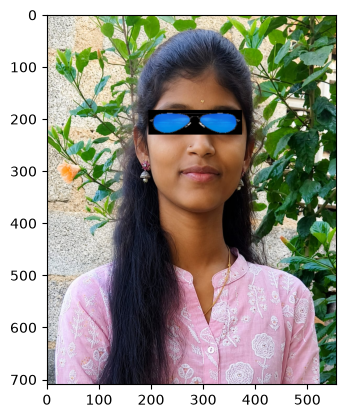

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Sunglasses position
x1, y1 = 390, 365
x2, y2 = 750, 460

# Resize sunglasses to fit both eyes
glassResized = cv2.resize(glassBGR, (x2-x1, y2-y1))

# Place sunglasses
faceWithGlassesNaive[y1:y2, x1:x2] = glassResized

# Display image
plt.imshow(faceWithGlassesNaive[:, :, ::-1])

# Change axis labels without zooming
plt.xticks(np.arange(0, 1100, 200),
           np.arange(0, 550, 100))

plt.yticks(np.arange(0, 1500, 200),
           np.arange(0, 750, 100))

plt.show()

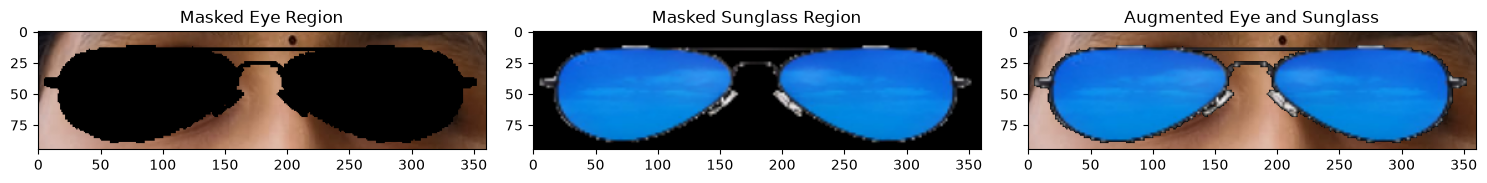

In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Sunglass position
x1, y1 = 390, 365
x2, y2 = 750, 460

# Resize sunglass
glass = cv2.resize(glassBGR, (x2-x1, y2-y1))

# Create mask from sunglass image
gray = cv2.cvtColor(glass, cv2.COLOR_BGR2GRAY)

# Remove black background
_, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)

# Get eye region
eyeROI = faceWithGlassesArithmetic[y1:y2, x1:x2]

# Masked Eye Region
maskedEye = cv2.bitwise_and(
    eyeROI, eyeROI,
    mask=cv2.bitwise_not(mask)
)

# Masked Sunglass Region
maskedGlass = cv2.bitwise_and(
    glass, glass,
    mask=mask
)

# Augmented Eye and Sunglass
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Place sunglasses on face
faceWithGlassesArithmetic[y1:y2, x1:x2] = eyeRoiFinal

# Display 3 outputs
plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(cv2.cvtColor(maskedEye, cv2.COLOR_BGR2RGB))
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(cv2.cvtColor(maskedGlass, cv2.COLOR_BGR2RGB))
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(cv2.cvtColor(eyeRoiFinal, cv2.COLOR_BGR2RGB))
plt.title("Augmented Eye and Sunglass")

plt.tight_layout()
plt.show()

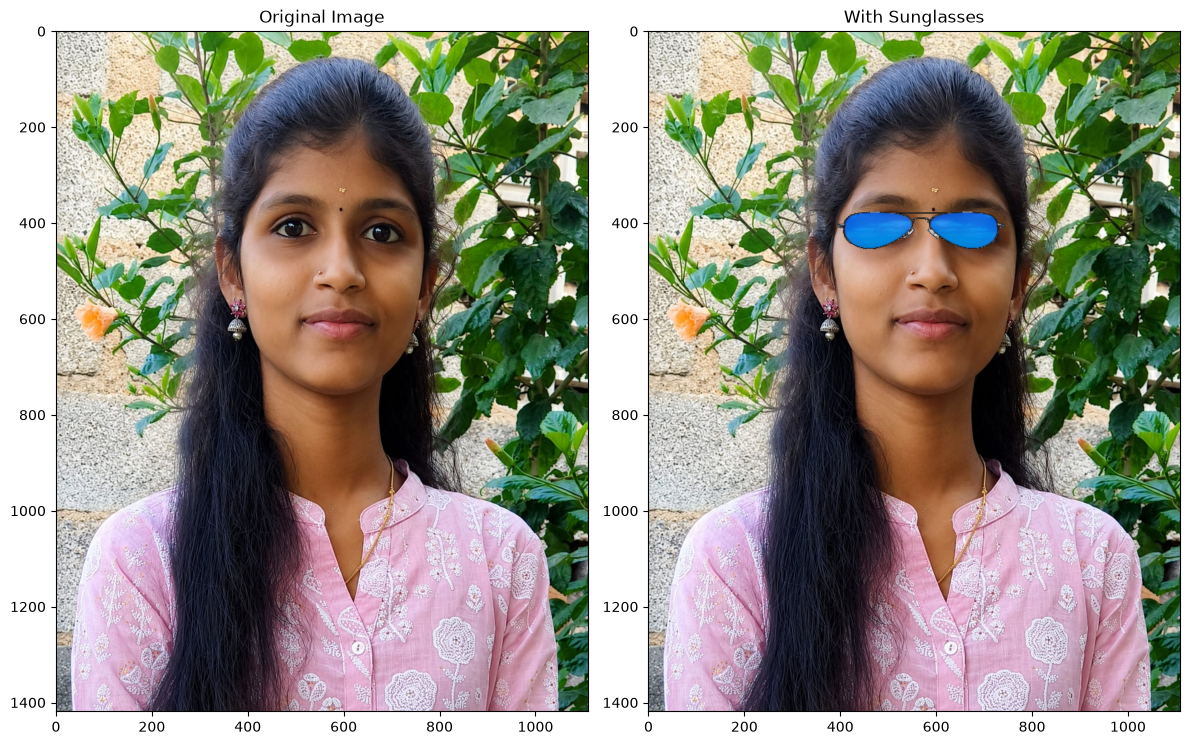

In [41]:
# Replace the eye ROI with sunglasses
faceWithGlassesArithmetic[365:460, 390:750] = eyeRoiFinal

# Display the final result
plt.figure(figsize=(12, 8))

plt.subplot(121)
plt.imshow(faceImage[:, :, ::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("With Sunglasses")

plt.tight_layout()
plt.show()